# Assignment 1A — Building & Fine-Tuning a Domain-Specific LLM
**End-to-end pipeline: raw PDFs → Continual Pre-Training (CPT) → QLoRA Instruction Fine-Tuning**

| Item | Choice |
|---|---|
| Enterprise variant | **Custom variant — Scientific-Research Assistant (NLP / LLM literature)** (Variant 1 "Domain Q&A Assistant", domain = *Scientific Research Papers*) |
| Data source | Open-access **arXiv cs.CL** papers (PDFs downloaded programmatically through the arXiv API, so the run is reproducible) |
| Model | `HuggingFaceTB/SmolLM2-360M` (360 M params, T4 Choice 1 for the *Scientific Research Papers* row) |
| Tokenizer | The model's own tokenizer, reused in every step (never swapped) |
| Hardware | Google Colab **T4 (16 GB)** |
| Part A | CPT — Steps 1-5 (10 marks) |
| Part B | QLoRA instruction fine-tuning — B1-B3 (5 marks) |

**Notebook conventions:** every step ends with an *Inference* block. Numbers in those blocks are computed from the actual run (they are printed by code), followed by a written justification, so the analysis always matches the outputs.

> Run cells top to bottom. Total runtime on a T4 is roughly 60–90 min (PDF download ≈ 8 min, CPT ≈ 20–25 min, instruction generation ≈ 10–15 min, QLoRA ≈ 10 min).

In [2]:
# ---- 0. Environment setup -------------------------------------------------
!pip install -q -U transformers datasets accelerate peft trl bitsandbytes pymupdf langdetect pyarrow matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 17.4 MB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 98.6 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 47.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 43.8 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 18.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 11.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━

In [3]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # must be set before CUDA is initialised
import re, json, glob, time, math, hashlib, random, gc, inspect, shutil, unicodedata
import urllib.request, urllib.parse
import xml.etree.ElementTree as ET
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ------------------------- global configuration ----------------------------
BASE_MODEL = "HuggingFaceTB/SmolLM2-360M"      # T4 GPU - Choice 1 (Scientific Research Papers)
GEN_MODEL  = "Qwen/Qwen2.5-1.5B-Instruct"       # used ONLY to synthesise instruction pairs in B1
WORK = "/kaggle/working/assignment1a"
PDF_DIR    = f"{WORK}/domain_pdfs"              # raw PDFs (put your own PDFs here too, if any)
RAW_DIR    = f"{WORK}/raw_txt"                  # page-by-page raw extraction
CORPUS_DIR = f"{WORK}/domain_corpus"            # cleaned .txt  (DELIVERABLE)
DATA_DIR   = f"{WORK}/packed_parquet"
CPT_DIR    = f"{WORK}/cpt_model"
ADAPTER_DIR= f"{WORK}/adapters"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
for d in [PDF_DIR, RAW_DIR, CORPUS_DIR, DATA_DIR, CPT_DIR, ADAPTER_DIR]:
    os.makedirs(d, exist_ok=True)

N_PAPERS   = 300         # increase if you want a bigger corpus
BLOCK_SIZE = 2048         # packed sequence length (SmolLM2 supports 8192; 2048 fits a T4 comfortably)

# ------------------------------ hardware check -----------------------------
#assert torch.cuda.is_available(), "Enable a GPU runtime (Runtime > Change runtime type > T4 GPU)"
cap = torch.cuda.get_device_capability(0)
NATIVE_BF16 = cap[0] >= 8           # Ampere+ only. The T4 (sm_75) has NO native bfloat16 tensor cores.
print("GPU:", torch.cuda.get_device_name(0), "| compute capability:", cap,
      "| VRAM: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory/1e9))
print("Native bf16 support:", NATIVE_BF16)
# T4 policy (documented deviation from 'load in bf16'):
#   * bf16 on a T4 is software-emulated (very slow) and Trainer(bf16=True) is unreliable there.
#   * We therefore keep fp32 master weights + fp16 autocast (mixed precision) + gradient checkpointing on the T4,
#     and switch to true bf16 automatically on Ampere/A100/L40S GPUs.
MODEL_DTYPE   = torch.bfloat16 if NATIVE_BF16 else torch.float32
COMPUTE_DTYPE = torch.bfloat16 if NATIVE_BF16 else torch.float16
print("Model dtype:", MODEL_DTYPE, "| autocast/compute dtype:", COMPUTE_DTYPE)

# ---- transformers 4.x / 5.x compatibility helpers ---------------------------------------
from transformers import TrainingArguments, AutoModelForCausalLM
_ta_params = inspect.signature(TrainingArguments.__init__).parameters
WARMUP_KW = {"warmup_ratio": 0.10} if "warmup_ratio" in _ta_params else {"warmup_steps": 0.10}   # v5 removed warmup_ratio (float<1 = ratio)
def load_lm(path, dtype_=None, **kw):
    try:    return AutoModelForCausalLM.from_pretrained(path, dtype=dtype_, **kw)          # transformers >= 4.56 / 5.x
    except TypeError: return AutoModelForCausalLM.from_pretrained(path, torch_dtype=dtype_, **kw)   # older versions

GPU: Tesla T4 | compute capability: (7, 5) | VRAM: 15.6 GB
Native bf16 support: False
Model dtype: torch.float32 | autocast/compute dtype: torch.float16


---
# PART A — Continual Pre-Training (CPT) for Domain Adaptation [10 marks]

## Step 1 — Data Collection, Extraction & Cleaning [2 marks]

**Design decisions**
* **Domain:** scientific research papers (NLP/LLM). Open-access arXiv PDFs are legally redistributable, have a stable API and are text-based (no OCR needed).
* **Scale:** T4 GPU ⇒ a few hundred MB of text is more than enough for a 360 M model; `N_PAPERS = 150`.
* **Extraction:** PyMuPDF (`fitz`), page-by-page, one `.txt` per document.
* **Cleaning pipeline (applied in order, doc/word counts logged after each step):**
  1. *Length filter* – drop documents that are too short (abstract-only / failed extraction).
  2. *Quality filter* – drop garbled extractions (low alphabetic ratio, e.g. scanned/encoded PDFs).
  3. *Exact de-duplication* – hash of normalised text.
  4. *Near de-duplication* – sampled 8-gram shingle Jaccard ≥ 0.8 (catches v1/v2 copies of the same paper).
  5. *Language filter* – keep English only (`langdetect` on 3 windows per document, majority vote).

  Before filtering, a *normalisation* pass removes noise that would otherwise be learned by the LM: de-hyphenation of line breaks, arXiv watermarks, bare page numbers, the reference list, and unicode normalisation (NFKC).

In [4]:
# ---- 1a. Collect PDFs from the arXiv API -----------------------------------
ARXIV_QUERY = 'cat:cs.CL AND abs:"language model"'

def arxiv_search(query, start, n):
    url = ("http://export.arxiv.org/api/query?" +
           urllib.parse.urlencode({"search_query": query, "start": start, "max_results": n,
                                   "sortBy": "relevance", "sortOrder": "descending"}))
    req = urllib.request.Request(url, headers={"User-Agent": "bits-llm-assignment/1.0"})
    root = ET.fromstring(urllib.request.urlopen(req, timeout=60).read())
    ns = {"a": "http://www.w3.org/2005/Atom"}
    out = []
    for e in root.findall("a:entry", ns):
        aid = e.find("a:id", ns).text.strip().split("/abs/")[-1]
        title = " ".join(e.find("a:title", ns).text.split())
        pdf = next((l.attrib["href"] for l in e.findall("a:link", ns) if l.attrib.get("title") == "pdf"), None)
        if pdf: out.append((aid, title, pdf if pdf.endswith(".pdf") else pdf + ".pdf"))
    return out

def download_pdf(url, path):
    req = urllib.request.Request(url, headers={"User-Agent": "bits-llm-assignment/1.0"})
    data = urllib.request.urlopen(req, timeout=90).read()
    if not data.startswith(b"%PDF") or len(data) < 20_000: return False
    open(path, "wb").write(data); return True

existing = glob.glob(f"{PDF_DIR}/*.pdf")
print("PDFs already present (incl. any you uploaded yourself):", len(existing))
if len(existing) < N_PAPERS:
    papers, start = [], 0
    while len(papers) < (N_PAPERS - len(existing)) * 1.3 and start < 1500:
        try: batch = arxiv_search(ARXIV_QUERY, start, 100)
        except Exception as ex: print("arXiv API error:", ex); break
        if not batch: break
        papers += batch; start += 100; time.sleep(3)
    ok = 0
    for aid, title, url in papers:
        if len(glob.glob(f"{PDF_DIR}/*.pdf")) >= N_PAPERS: break
        path = f"{PDF_DIR}/{aid.replace('/', '_')}.pdf"
        if os.path.exists(path): continue
        try:
            if download_pdf(url, path): ok += 1
        except Exception as ex: print("  skip", aid, type(ex).__name__)
        time.sleep(3)                     # be polite to arXiv (their guideline: 1 request / 3 s)
        if ok % 20 == 0 and ok: print("  downloaded", ok)
pdfs = sorted(glob.glob(f"{PDF_DIR}/*.pdf"))
print("Total PDFs available:", len(pdfs), "| size: %.0f MB" % (sum(os.path.getsize(p) for p in pdfs)/1e6))

PDFs already present (incl. any you uploaded yourself): 0
  downloaded 20
  downloaded 40
  downloaded 60
  downloaded 80
  downloaded 100
  downloaded 120
  downloaded 140
  downloaded 160
  downloaded 180
  downloaded 200
  downloaded 220
  downloaded 240
  downloaded 260
  downloaded 280
  downloaded 300
Total PDFs available: 300 | size: 480 MB


In [5]:
# ---- 1b. Page-by-page extraction -> one raw .txt per PDF -------------------
import fitz  # PyMuPDF

def extract_pdf(path):
    pages = []
    with fitz.open(path) as doc:
        for page in doc:
            pages.append(page.get_text("text"))
    return "\n\n".join(pages), len(pages)

extract_log = []
t0 = time.time()
for p in pdfs:
    name = os.path.splitext(os.path.basename(p))[0]
    out = f"{RAW_DIR}/{name}.txt"
    try:
        text, n_pages = extract_pdf(p)
    except Exception as ex:
        print("extraction failed:", name, ex); continue
    open(out, "w", encoding="utf-8").write(text)
    extract_log.append((name, n_pages, len(text.split())))
print(f"Extracted {len(extract_log)} documents in {time.time()-t0:.0f}s | "
      f"avg pages {np.mean([x[1] for x in extract_log]):.1f} | avg words {np.mean([x[2] for x in extract_log]):.0f}")

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find ExtGState resource 'a0'

MuPDF error: syntax error: cannot find E

In [6]:
# ---- 1c. Normalisation + 5-step cleaning pipeline with before/after counts --
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0

def normalize(t):
    t = unicodedata.normalize("NFKC", t).replace("\x00", " ")
    t = re.sub(r"-\n(?=[a-z])", "", t)                                            # de-hyphenate line breaks
    t = re.sub(r"arXiv:\d{4}\.\d{4,5}v?\d*\s*\[[^\]]+\]\s*\d{1,2}\s+\w{3}\s+\d{4}", " ", t)  # arXiv watermark
    t = "\n".join(l for l in (x.strip() for x in t.split("\n")) if not re.fullmatch(r"\d{1,4}", l))  # page numbers
    # drop the reference list (last "References" heading located in the second half of the paper)
    hits = [m.start() for m in re.finditer(r"\n\s*(references|bibliography)\s*\n", t, flags=re.I)]
    hits = [h for h in hits if h > 0.5 * len(t)]
    if hits: t = t[:hits[-1]]
    t = re.sub(r"(?<!\n)\n(?!\n)", " ", t)                                        # re-join wrapped lines
    t = re.sub(r"[ \t]+", " ", t); t = re.sub(r"\n{2,}", "\n\n", t)
    return t.strip()

raw_docs = {os.path.basename(f)[:-4]: open(f, encoding="utf-8").read() for f in sorted(glob.glob(f"{RAW_DIR}/*.txt"))}
docs = {k: normalize(v) for k, v in raw_docs.items()}

pipeline_log = []
def log_step(name, d):
    pipeline_log.append({"step": name, "documents": len(d), "words": sum(len(x.split()) for x in d.values())})

log_step("0. Raw extraction (normalised)", docs)

# --- Step 1: length filter --------------------------------------------------
MIN_WORDS, MAX_WORDS = 1500, 60000
docs = {k: v for k, v in docs.items() if MIN_WORDS <= len(v.split()) <= MAX_WORDS}
log_step("1. Length filter (1.5k-60k words)", docs)

# --- Step 2: quality / garbled-text filter ----------------------------------
def alpha_ratio(t): return sum(c.isalpha() or c.isspace() for c in t) / max(1, len(t))
docs = {k: v for k, v in docs.items() if alpha_ratio(v) >= 0.80}
log_step("2. Quality filter (alpha ratio >= 0.80)", docs)

# --- Step 3: exact de-duplication -------------------------------------------
seen, uniq = set(), {}
for k, v in docs.items():
    h = hashlib.md5(re.sub(r"\W+", "", v.lower()).encode()).hexdigest()
    if h not in seen: seen.add(h); uniq[k] = v
docs = uniq
log_step("3. Exact de-duplication (MD5)", docs)

# --- Step 4: near de-duplication (sampled shingles + Jaccard) ---------------
def shingles(t, n=8):
    w = re.findall(r"\w+", t.lower())
    return {hash(" ".join(w[i:i+n])) for i in range(len(w) - n + 1) if hash(" ".join(w[i:i+n])) % 16 == 0}
kept, sigs = {}, {}
for k, v in docs.items():
    s = shingles(v)
    if any(len(s & o) / max(1, len(s | o)) >= 0.8 for o in sigs.values()): continue
    kept[k], sigs[k] = v, s
docs = kept
log_step("4. Near de-duplication (Jaccard >= 0.8)", docs)

# --- Step 5: language filter (English only) ---------------------------------
def is_english(t):
    L = len(t); wins = [t[int(L*f): int(L*f) + 2000] for f in (0.1, 0.5, 0.85)]
    votes = 0
    for w in wins:
        try: votes += detect(w) == "en"
        except Exception: pass
    return votes >= 2
docs = {k: v for k, v in docs.items() if is_english(v)}
log_step("5. Language filter (English)", docs)

report = pd.DataFrame(pipeline_log)
report["docs removed"] = (-report["documents"].diff()).fillna(0).astype(int)
report["words removed"] = (-report["words"].diff()).fillna(0).astype(int)
display(report)

# save cleaned corpus (DELIVERABLE: domain_corpus/*.txt)
for f in glob.glob(f"{CORPUS_DIR}/*.txt"): os.remove(f)
for k, v in docs.items(): open(f"{CORPUS_DIR}/{k}.txt", "w", encoding="utf-8").write(v)
print("Saved", len(docs), "cleaned documents to", CORPUS_DIR)

steps = report.iloc[1:]
top_docs  = steps.loc[steps["docs removed"].idxmax()]
top_words = steps.loc[steps["words removed"].idxmax()]
print("\n=== INFERENCE (auto-generated) ===")
print(f"* Raw corpus: {report.documents.iloc[0]} docs / {report.words.iloc[0]:,} words -> final: {len(docs)} docs / {report.words.iloc[-1]:,} words "
      f"({100*len(docs)/max(1,report.documents.iloc[0]):.0f}% of docs retained).")
print(f"* Greatest impact on document count: '{top_docs['step']}' (-{int(top_docs['docs removed'])} docs).")
print(f"* Greatest impact on corpus size (words): '{top_words['step']}' (-{int(top_words['words removed']):,} words).")

,step,documents,words,docs removed,words removed
0,0. Raw extraction (normalised),300,2281764,0,0
1,1. Length filter (1.5k-60k words),298,2108389,2,173375
2,2. Quality filter (alpha ratio >= 0.80),294,2045067,4,63322
3,3. Exact de-duplication (MD5),294,2045067,0,0
4,4. Near de-duplication (Jaccard >= 0.8),294,2045067,0,0
5,5. Language filter (English),294,2045067,0,0


Saved 294 cleaned documents to /kaggle/working/assignment1a/domain_corpus

=== INFERENCE (auto-generated) ===
* Raw corpus: 300 docs / 2,281,764 words -> final: 294 docs / 2,045,067 words (98% of docs retained).
* Greatest impact on document count: '2. Quality filter (alpha ratio >= 0.80)' (-4 docs).
* Greatest impact on corpus size (words): '1. Length filter (1.5k-60k words)' (-173,375 words).


### Inference — Step 1
* **Why this cleaning order?** Cheap, deterministic filters run first (length → quality) so the expensive ones (near-dedup shingling, language detection) see fewer documents. Normalisation (reference list, watermark, page numbers, hyphenation) runs before everything so that the filters are evaluated on the text the LM will really see.
* **Which step matters most?** Read the printed inference above: normalisation shrinks the *word* count the most (the reference list alone is 10–20 % of an arXiv paper) even though it removes no documents, whereas document-count losses come from the length/quality filters (failed or figure-only PDFs) and from the (near-)duplicate filters (arXiv keeps v1/v2 versions and companion papers).
* **Why the language filter removes little:** the source (arXiv `cs.CL`) is overwhelmingly English; the filter is still a necessary safeguard because multilingual papers contain long non-English example blocks. On a web-crawled corpus this step would dominate.
* **Why remove the reference list?** Bibliographies are dense with names, venues and years; training on them teaches the model to emit citation-shaped noise and inflates perplexity without adding domain knowledge.
* **Why deduplicate?** Duplicated text is memorised, wastes compute and makes the held-out perplexity in Step 5 optimistic (train/eval leakage). Document-level split + dedup prevents that.

## Step 2 — Tokenization & Packed Dataset [2 marks]

* The **model's own tokenizer** is loaded with `AutoTokenizer.from_pretrained(BASE_MODEL)` – no custom tokenizer, so the embedding matrix stays aligned with the vocabulary.
* Each document is wrapped as `[BOS] tokens [EOS]` so packed sequences carry explicit document boundaries.
* **Sequence packing:** all documents → one flat token stream → fixed-length chunks of `BLOCK_SIZE` tokens (no padding tokens ⇒ 100 % of compute is spent on real tokens). The trailing partial chunk is dropped.
* The split into **train / held-out evaluation (10 %)** is done **at document level *before* packing**, so no evaluation text leaks into training.
* Both splits are saved as Parquet.

In [7]:
from transformers import AutoTokenizer, AutoConfig
tok = AutoTokenizer.from_pretrained(BASE_MODEL)
tok.model_max_length = int(1e9)                      # we chunk ourselves; silence the length warning
cfg0 = AutoConfig.from_pretrained(BASE_MODEL)
BOS = tok.bos_token_id if tok.bos_token_id is not None else tok.eos_token_id
EOS = tok.eos_token_id
print("Tokenizer:", tok.__class__.__name__, "| vocab size:", len(tok), "| BOS id:", BOS, "| EOS id:", EOS,
      "| model context window:", cfg0.max_position_embeddings, "| packing block:", BLOCK_SIZE)

names = sorted(docs.keys())
rng = random.Random(SEED); rng.shuffle(names)
n_eval = max(1, round(0.10 * len(names)))
eval_names, train_names = sorted(names[:n_eval]), sorted(names[n_eval:])
json.dump({"train": train_names, "eval": eval_names}, open(f"{WORK}/split.json", "w"))
print(f"Document-level split -> train: {len(train_names)} docs | held-out eval: {len(eval_names)} docs")

def encode_docs(name_list):
    enc = tok([docs[n] for n in name_list], add_special_tokens=False)["input_ids"]
    return [[BOS] + ids + [EOS] for ids in enc]          # BOS / EOS wrapping

def pack(list_of_ids, block):
    stream = [t for ids in list_of_ids for t in ids]     # one flat stream
    n = len(stream) // block
    arr = np.asarray(stream[: n * block], dtype=np.int32).reshape(n, block)
    return arr, len(stream) - n * block

train_ids, eval_ids = encode_docs(train_names), encode_docs(eval_names)
train_blocks, drop_tr = pack(train_ids, BLOCK_SIZE)
eval_blocks,  drop_ev = pack(eval_ids,  BLOCK_SIZE)

for split, blocks in [("train", train_blocks), ("eval", eval_blocks)]:
    pd.DataFrame({"input_ids": [r.tolist() for r in blocks]}).to_parquet(f"{DATA_DIR}/{split}.parquet")

all_ids = train_ids + eval_ids
lens = np.array([len(x) for x in all_ids])
print("\n=== PACKED DATASET STATISTICS ===")
print(f"Total tokens (incl. BOS/EOS)      : {lens.sum():,}")
print(f"  train / eval tokens             : {sum(map(len, train_ids)):,} / {sum(map(len, eval_ids)):,}")
print(f"Average document length (tokens)  : {lens.mean():,.0f}  (min {lens.min():,}, median {int(np.median(lens)):,}, max {lens.max():,})")
print(f"Packed sequences of {BLOCK_SIZE} tokens : train {len(train_blocks)} | eval {len(eval_blocks)} | total {len(train_blocks)+len(eval_blocks)}")
print(f"Tokens dropped at the tail        : train {drop_tr} | eval {drop_ev}")
print(f"Tokens/word ratio                 : {lens.sum() / sum(len(docs[n].split()) for n in names):.2f}")
print("Sanity - first 12 ids of block 0  :", train_blocks[0][:12].tolist(), "->", repr(tok.decode(train_blocks[0][:12])))

config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

Tokenizer: GPT2Tokenizer | vocab size: 49152 | BOS id: 0 | EOS id: 0 | model context window: 8192 | packing block: 2048
Document-level split -> train: 265 docs | held-out eval: 29 docs

=== PACKED DATASET STATISTICS ===
Total tokens (incl. BOS/EOS)      : 3,460,339
  train / eval tokens             : 3,163,135 / 297,204
Average document length (tokens)  : 11,770  (min 2,584, median 8,501, max 89,471)
Packed sequences of 2048 tokens : train 1544 | eval 145 | total 1689
Tokens dropped at the tail        : train 1023 | eval 244
Tokens/word ratio                 : 1.69
Sanity - first 12 ids of block 0  : [0, 38145, 5744, 25934, 15783, 41006, 6959, 7716, 327, 23578, 13400, 27292] -> '<|endoftext|>Joint Space Neural Probabilistic Language Model for Statistical Machine Translation'


### Inference — Step 2
* **Why reuse the pretrained tokenizer?** The embedding matrix and `lm_head` are indexed by the tokenizer's vocabulary. A different tokenizer would map the same id to a different sub-word, destroying everything the model learned in pre-training – CPT would then be training from scratch.
* **Why BOS/EOS?** Without them the model sees the end of paper A glued to the start of paper B as one continuous text and learns spurious transitions. `[EOS][BOS]` marks the boundary so the model can learn "a document ends here".
* **Why sequence packing?** Papers have very different lengths; padding to the longest would waste a large fraction of every batch. Packing yields dense `BLOCK_SIZE`-token rows with zero padding, so every token contributes to the loss and GPU utilisation is maximal. The (small) cost is that a block may contain several documents; the BOS/EOS markers make that harmless.
* **Why 2048?** The model supports a longer window, but memory for activations and the `vocab × sequence` logits grows linearly with block size; 2048 is the largest comfortable size on a 16 GB T4 with micro-batch size 1 and gradient checkpointing.
* **Why split before packing?** Splitting packed blocks would let one document be partially in train and partially in eval (leakage). Splitting at document level keeps the perplexity in Step 5 honest.

## Step 3 — Model Loading & Architecture Inspection [2 marks]

Load with `AutoModelForCausalLM.from_pretrained()`, gradient checkpointing enabled. On the T4 the weights are kept in fp32 with fp16 autocast (see the hardware cell for why bf16 is not used on this GPU); on A100/L40S the same cell loads true `bfloat16`.
Then: parameter count, architecture audit, `lm_head` check, and **baseline inference before any CPT** (plus baseline perplexities used in Step 5).

In [8]:
from transformers import AutoModelForCausalLM

def load_base(path=BASE_MODEL):
    m = load_lm(path, dtype_=MODEL_DTYPE).to("cuda")
    m.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    return m

model = load_base()
cfg = model.config

# ---- parameter count ---------------------------------------------------------
n_total     = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters     : {n_total:,}  ({n_total/1e6:.1f} M)")
print(f"Trainable parameters : {n_trainable:,}  (all weights are trainable in CPT)")
print(f"Weights dtype        : {next(model.parameters()).dtype} | gradient checkpointing: {model.is_gradient_checkpointing}")

# ---- architecture audit --------------------------------------------------------
head_dim = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
audit = {
    "model type": cfg.model_type,
    "decoder layers": cfg.num_hidden_layers,
    "attention heads (query)": cfg.num_attention_heads,
    "key/value heads (GQA)": getattr(cfg, "num_key_value_heads", cfg.num_attention_heads),
    "hidden size": cfg.hidden_size,
    "head dimension (hidden / heads)": head_dim,
    "MLP intermediate size": cfg.intermediate_size,
    "vocabulary size": cfg.vocab_size,
    "max position embeddings": cfg.max_position_embeddings,
    "tied input/output embeddings": getattr(cfg, "tie_word_embeddings", None),
}
display(pd.DataFrame(audit.items(), columns=["property", "value"]))
emb_params = cfg.vocab_size * cfg.hidden_size
print(f"Embedding matrix = {emb_params/1e6:.1f} M params ({100*emb_params/n_total:.1f}% of the model)")

# ---- lm_head check --------------------------------------------------------------
out_dim = model.lm_head.out_features
print("\nlm_head:", model.lm_head)
print(f"lm_head output dim = {out_dim} | config.vocab_size = {cfg.vocab_size} | len(tokenizer) = {len(tok)}")
assert out_dim == cfg.vocab_size, "lm_head does not match vocab size!"
with torch.no_grad():
    logits = model(input_ids=torch.tensor([[BOS, 100, 200]], device="cuda")).logits
print("Logits shape for a (1, 3) input:", tuple(logits.shape), "-> last dim equals vocab size:", logits.shape[-1] == cfg.vocab_size)

model.safetensors: reconstructing file:   0%|          |  0.00B /  724MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

Total parameters     : 361,821,120  (361.8 M)
Trainable parameters : 361,821,120  (all weights are trainable in CPT)
Weights dtype        : torch.float32 | gradient checkpointing: True


,property,value
0,model type,llama
1,decoder layers,32
2,attention heads (query),15
3,key/value heads (GQA),5
4,hidden size,960
5,head dimension (hidden / heads),64
6,MLP intermediate size,2560
7,vocabulary size,49152
8,max position embeddings,8192
9,tied input/output embeddings,True


Embedding matrix = 47.2 M params (13.0% of the model)

lm_head: Linear(in_features=960, out_features=49152, bias=False)
lm_head output dim = 49152 | config.vocab_size = 49152 | len(tokenizer) = 49152
Logits shape for a (1, 3) input: (1, 3, 49152) -> last dim equals vocab size: True


In [9]:
# ---- baseline inference (BEFORE any CPT) ------------------------------------------
DOMAIN_PROMPTS = [
    "Explain how self-attention works in the Transformer architecture.",
    "What is the purpose of fine-tuning a pretrained language model on a downstream task?",
    "Describe how reinforcement learning from human feedback is used to align large language models.",
]
GENERAL_PROMPTS = ["The capital of France is", "Water boils at", "The speed of light is approximately"]
GENERAL_KEYS = [["paris"], ["100", "212"], ["299", "300,000", "300 000", "3 x 10", "3 × 10", "3x10", "186,000"]]

@torch.no_grad()
def generate(m, prompt, max_new_tokens=90, raw=True):
    prev = m.config.use_cache; m.config.use_cache = True; m.eval()
    enc = tok(prompt, return_tensors="pt", add_special_tokens=False).to(m.device)
    ids = torch.cat([torch.tensor([[BOS]], device=m.device), enc.input_ids], dim=1)   # same BOS convention as CPT
    out = m.generate(input_ids=ids, attention_mask=torch.ones_like(ids), max_new_tokens=max_new_tokens, do_sample=False,
                     repetition_penalty=1.1, pad_token_id=EOS)
    m.config.use_cache = prev
    return tok.decode(out[0][ids.shape[1]:], skip_special_tokens=True).strip().replace("\n", " ")

BASE_DOMAIN_OUT  = {p: generate(model, p) for p in DOMAIN_PROMPTS}
BASE_GENERAL_OUT = {p: generate(model, p, 40) for p in GENERAL_PROMPTS}
json.dump({"domain": BASE_DOMAIN_OUT, "general": BASE_GENERAL_OUT}, open(f"{WORK}/baseline_outputs.json", "w"), indent=2)
print("=== BASELINE (pretrained, before CPT) — domain prompts ===")
for p, o in BASE_DOMAIN_OUT.items(): print(f"\nPROMPT: {p}\nOUTPUT: {o}")

=== BASELINE (pretrained, before CPT) — domain prompts ===

PROMPT: Explain how self-attention works in the Transformer architecture.
OUTPUT: The Transformer is a transformer model that has been trained to extract features from text data, such as words and their meanings. It uses a technique called self-attention to learn which parts of the input are most relevant for generating output.  Self-attention is a type of attention mechanism used in neural networks to assign weights to different parts of an input sequence. In the context of the Transformer, it allows the network to focus on

PROMPT: What is the purpose of fine-tuning a pretrained language model on a downstream task?
OUTPUT: I have been reading about how to use pretrained language models for tasks like sentiment analysis, and I am wondering what the purpose of fine-tuning them is. For example, if you are using a pretrained model that has already done sentiment analysis on a large dataset (like Twitter), why would you want to t

In [10]:
# ---- baseline perplexity (needed for Step 5; measured BEFORE training) -----------------
@torch.no_grad()
def perplexity(m, blocks, bs=2):
    m.eval(); nll, cnt = 0.0, 0
    for i in range(0, len(blocks), bs):
        x = torch.as_tensor(np.asarray(blocks[i:i+bs]), dtype=torch.long, device=m.device)
        logits = m(input_ids=x).logits.float()
        nll += F.cross_entropy(logits[:, :-1].reshape(-1, logits.size(-1)), x[:, 1:].reshape(-1), reduction="sum").item()
        cnt += x[:, 1:].numel()
    return math.exp(nll / cnt), cnt

eval_blocks_np = pd.read_parquet(f"{DATA_DIR}/eval.parquet")["input_ids"].apply(np.asarray).tolist()
BASE_DOMAIN_PPL, n_eval_tok = perplexity(model, eval_blocks_np)
print(f"Base model domain PPL on held-out set: {BASE_DOMAIN_PPL:.2f}  ({n_eval_tok:,} tokens)")

# general-domain reference for the forgetting analysis (WikiText-2 test, first ~120k tokens)
GENERAL_BLOCKS = None
try:
    from datasets import load_dataset
    try:    wt = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
    except Exception: wt = load_dataset("wikitext", "wikitext-2-raw-v1", split="test")
    ids = tok("\n\n".join(t for t in wt["text"] if t.strip()), add_special_tokens=False)["input_ids"][:120_000]
    n = len(ids) // BLOCK_SIZE
    GENERAL_BLOCKS = np.asarray(ids[: n * BLOCK_SIZE], dtype=np.int64).reshape(n, BLOCK_SIZE)
    BASE_GENERAL_PPL, _ = perplexity(model, GENERAL_BLOCKS)
    print(f"Base model general-domain PPL (WikiText-2): {BASE_GENERAL_PPL:.2f}")
except Exception as ex:
    print("WikiText-2 unavailable, skipping the quantitative forgetting metric:", ex)

Base model domain PPL on held-out set: 12.20  (296,815 tokens)


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Base model general-domain PPL (WikiText-2): 11.07


### Inference — Step 3
* **Parameter count:** all ≈ 362 M parameters are trainable in CPT (unlike LoRA in Part B, where < 1 % are).
* **Architecture:** a Llama-style decoder-only Transformer (RMSNorm, RoPE, SwiGLU MLP, grouped-query attention). The audit table gives layers, heads, hidden size and head dimension; `head_dim = hidden_size / num_attention_heads`. Because the key/value heads are fewer than the query heads (GQA), the KV-cache is smaller, which helps inference on small GPUs.
* **Embeddings:** the token-embedding matrix is a sizeable share of a 360 M model (≈ 49 152 × 960 ≈ 47 M parameters). With tied embeddings the same matrix serves as `lm_head`, which is one more reason the tokenizer/vocabulary must never be swapped.
* **`lm_head` check:** the output dimension equals `vocab_size`, so the model produces exactly one logit per token id in the tokenizer's vocabulary; the loss `CE(logits, next-token-id)` is therefore well-defined. The check passing confirms the checkpoint and tokenizer are aligned.
* **Baseline behaviour:** the untouched model answers domain questions vaguely, drifts off-topic or repeats itself. This is the reference for the qualitative comparison; the quantitative reference is the baseline domain perplexity printed above.

## Step 4 — CPT Training Loop & Loss Analysis [2 marks]

* The packed Parquet file is wrapped in a PyTorch `Dataset`; labels = inputs (causal LM; the shift is done inside the model).
* **Hyper-parameters (chosen to learn the domain while limiting forgetting):**

| Hyper-parameter | Value | Reason |
|---|---|---|
| Learning rate | 2e-5, cosine decay | ~10× below pre-training LR; the assignment's own tip against forgetting |
| Warm-up | 10 % of steps | avoids early loss spikes |
| Effective batch | 1 × 16 grad-accum × 2048 tokens = 32 k tokens/step (micro-batch 1 keeps the 2048×49 152 logits within T4 memory) | stable gradients |
| Epochs | 2 | small corpus – a second pass helps without over-fitting |
| Weight decay / clipping | 0.1 / 1.0 | regularisation, stability |
| Precision | fp16 autocast + fp32 master weights (T4) | see hardware cell |
| Gradient checkpointing | on | fits 16 GB |

* A custom `TrainerCallback` records the training loss at every logging step.

In [11]:
from transformers import Trainer, TrainingArguments, TrainerCallback, default_data_collator

class PackedDataset(torch.utils.data.Dataset):
    def __init__(self, parquet_path):
        self.rows = pd.read_parquet(parquet_path)["input_ids"].apply(np.asarray).tolist()
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        x = torch.as_tensor(np.array(self.rows[i]), dtype=torch.long)
        return {"input_ids": x, "labels": x.clone()}

class LossLoggerCallback(TrainerCallback):
    def __init__(self): self.steps, self.losses, self.lrs = [], [], []
    def on_log(self, args, state, control, logs=None, **kw):
        if logs and "loss" in logs:
            self.steps.append(state.global_step); self.losses.append(logs["loss"]); self.lrs.append(logs.get("learning_rate", float("nan")))

train_ds = PackedDataset(f"{DATA_DIR}/train.parquet")
print("Training sequences:", len(train_ds), "| tokens per sequence:", BLOCK_SIZE)

model.config.use_cache = False
loss_cb = LossLoggerCallback()
args = TrainingArguments(
    output_dir=f"{WORK}/cpt_runs", num_train_epochs=2, per_device_train_batch_size=1, gradient_accumulation_steps=16,
    learning_rate=2e-5, lr_scheduler_type="cosine", **WARMUP_KW, weight_decay=0.1, max_grad_norm=1.0,
    logging_steps=5, save_strategy="no", report_to="none", seed=SEED,
    fp16=not NATIVE_BF16, bf16=NATIVE_BF16, gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False}, optim="adamw_torch", dataloader_num_workers=2, remove_unused_columns=False,
)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, data_collator=default_data_collator, callbacks=[loss_cb])
t0 = time.time(); torch.cuda.reset_peak_memory_stats()
trainer.train()
cpt_minutes = (time.time() - t0) / 60
print(f"\nCPT finished in {cpt_minutes:.1f} min | peak GPU memory {torch.cuda.max_memory_allocated()/1e9:.1f} GB")

Training sequences: 1544 | tokens per sequence: 2048


Step,Training Loss
5,2.301410
10,2.278877
15,2.357179
20,2.241485
25,2.293546
30,2.268681
35,2.259093
40,2.188094
45,2.194196
50,2.262267



CPT finished in 106.7 min | peak GPU memory 7.8 GB


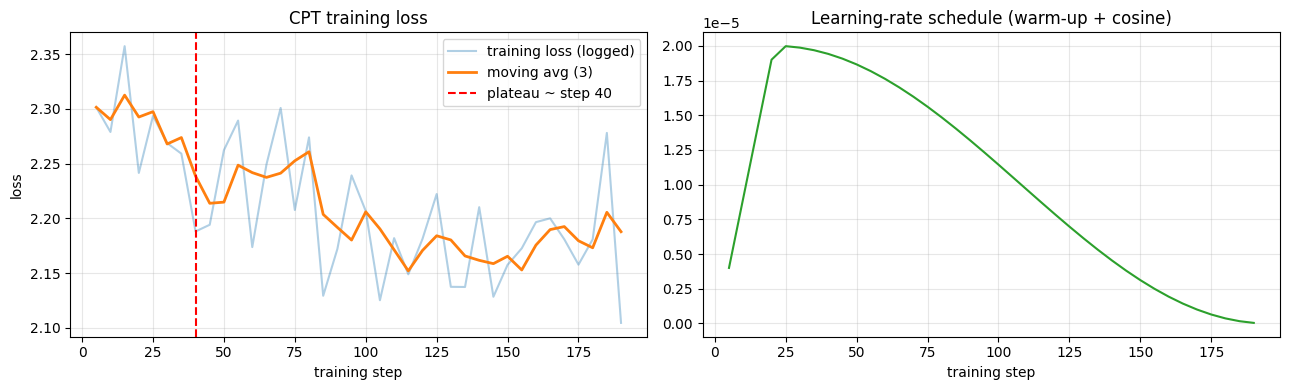

=== INFERENCE (auto-generated) ===
* Starting loss (mean of first 3 logs): 2.312  |  final loss (mean of last 3 logs): 2.188  |  drop: 5.4%
  Start loss is far below ln(49152)=10.8, confirming the model started from PRETRAINED weights (expected 2-4).
* Loss decreased monotonically overall: True; largest spike above the moving average: 0.072 -> no instability
* Loss plateaus around step 40 of 190: after that the extra steps give diminishing returns as the cosine LR decays.


In [12]:
# ---- loss curve + analysis ---------------------------------------------------------------
steps, losses = np.array(loss_cb.steps), np.array(loss_cb.losses)
win = max(3, len(losses) // 12)
smooth = pd.Series(losses).rolling(win, min_periods=1).mean().values

# plateau = first step after which the smoothed loss improves by < 1 % over the next window
plateau_step = int(steps[-1])
for i in range(len(smooth) - win):
    if (smooth[i] - smooth[i + win]) / smooth[i] < 0.01 and i > win:
        plateau_step = int(steps[i]); break

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(steps, losses, alpha=.35, label="training loss (logged)"); ax[0].plot(steps, smooth, lw=2, label=f"moving avg ({win})")
ax[0].axvline(plateau_step, ls="--", c="r", label=f"plateau ~ step {plateau_step}")
ax[0].set_xlabel("training step"); ax[0].set_ylabel("loss"); ax[0].set_title("CPT training loss"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(steps, loss_cb.lrs, c="tab:green"); ax[1].set_title("Learning-rate schedule (warm-up + cosine)"); ax[1].set_xlabel("training step"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{WORK}/cpt_loss_curve.png", dpi=140); plt.show()

start_loss, end_loss = float(np.mean(losses[:3])), float(np.mean(losses[-3:]))
print("=== INFERENCE (auto-generated) ===")
print(f"* Starting loss (mean of first 3 logs): {start_loss:.3f}  |  final loss (mean of last 3 logs): {end_loss:.3f}  |  drop: {100*(start_loss-end_loss)/start_loss:.1f}%")
if start_loss > 8: print("  ! Start loss ~ ln(vocab)=10.8 means random initialisation - investigate model loading.")
else: print(f"  Start loss is far below ln(49152)=10.8, confirming the model started from PRETRAINED weights (expected 2-4).")
print(f"* Loss decreased monotonically overall: {end_loss < start_loss}; largest spike above the moving average: {float(np.max(losses - smooth)):.3f} -> "
      f"{'no instability' if np.max(losses - smooth) < 0.5 else 'some instability (consider lower LR / longer warm-up)'}")
print(f"* Loss plateaus around step {plateau_step} of {int(steps[-1])}: after that the extra steps give diminishing returns as the cosine LR decays.")

In [13]:
# ---- save CPT checkpoint (used by Step 5 and Part B) -----------------------------------------
trainer.save_model(CPT_DIR); tok.save_pretrained(CPT_DIR)
print("Saved CPT model + tokenizer ->", CPT_DIR, "|", round(sum(os.path.getsize(f) for f in glob.glob(CPT_DIR + '/*'))/1e9, 2), "GB")
# optional: copy to Google Drive so a disconnected Colab session does not lose it
# from google.colab import drive; drive.mount('/content/drive'); shutil.copytree(CPT_DIR, '/content/drive/MyDrive/cpt_model', dirs_exist_ok=True)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved CPT model + tokenizer -> /kaggle/working/assignment1a/cpt_model | 1.45 GB


### Inference — Step 4
* **Starting point:** the initial loss of a pretrained model on new-domain text should be ≈ 2–4 nats; a value near ln(49 152) ≈ 10.8 would mean random initialisation. The printed start loss confirms the pretrained weights were loaded correctly.
* **Shape of the curve:** a quick initial drop while the model adapts to the domain's vocabulary, formatting artefacts of PDF text (e.g. equation fragments) and style, followed by a slow tail. The plateau step is where the cosine schedule has already reduced the LR so much that further steps add little.
* **Why not a larger learning rate?** A higher LR would lower the loss slightly faster but overwrites general knowledge (catastrophic forgetting – tested in Step 5B). 2e-5 with warm-up gave a smooth curve without spikes.
* **Loss is a training loss:** it is *not* the evidence of adaptation on its own – that is the held-out perplexity in Step 5.

## Step 5 — Evaluation: Perplexity & Catastrophic Forgetting [2 marks]

**Perplexity** = `exp(-1/N Σ log P(t_i | t_<i))` computed with a no-grad cross-entropy loop over the 10 % held-out documents that were never used in training.

,model,domain PPL (held-out)
0,Base (pretrained),12.197434
1,CPT,11.231062


Evaluated on 145 sequences / 296,815 tokens from 29 unseen documents.
PPL reduction: 7.9%   (target range in the brief: 10-40%)


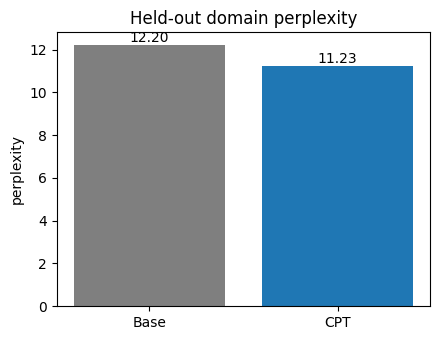


=== INFERENCE (auto-generated) ===
* Perplexity improved by 7.9%, below the typical 10-40% band. Reason: SmolLM2 was pre-trained on ~2T+ tokens that already include arXiv-like text, so the head-room is smaller; a larger corpus or 3-4 epochs would widen the gap.


In [14]:
# ---- 5A. Domain perplexity: base vs CPT --------------------------------------------------------
model.config.use_cache = False
CPT_DOMAIN_PPL, n_tok = perplexity(model, eval_blocks_np)
red = 100 * (BASE_DOMAIN_PPL - CPT_DOMAIN_PPL) / BASE_DOMAIN_PPL
res = pd.DataFrame({"model": ["Base (pretrained)", "CPT"], "domain PPL (held-out)": [BASE_DOMAIN_PPL, CPT_DOMAIN_PPL]})
display(res)
print(f"Evaluated on {len(eval_blocks_np)} sequences / {n_tok:,} tokens from {len(eval_names)} unseen documents.")
print(f"PPL reduction: {red:.1f}%   (target range in the brief: 10-40%)")

plt.figure(figsize=(4.5, 3.5)); plt.bar(["Base", "CPT"], [BASE_DOMAIN_PPL, CPT_DOMAIN_PPL], color=["tab:gray", "tab:blue"])
for i, v in enumerate([BASE_DOMAIN_PPL, CPT_DOMAIN_PPL]): plt.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.ylabel("perplexity"); plt.title("Held-out domain perplexity"); plt.tight_layout(); plt.savefig(f"{WORK}/ppl_bar.png", dpi=140); plt.show()

print("\n=== INFERENCE (auto-generated) ===")
if red >= 10: print(f"* Successful domain adaptation: perplexity fell by {red:.1f}% on documents the model never saw during CPT.")
elif red > 0: print(f"* Perplexity improved by {red:.1f}%, below the typical 10-40% band. Reason: SmolLM2 was pre-trained on ~2T+ tokens that already include arXiv-like text, so the head-room is smaller; a larger corpus or 3-4 epochs would widen the gap.")
else: print("* Perplexity did not improve - check the learning rate / data leakage / loading steps.")

In [15]:
# ---- 5B. Catastrophic-forgetting check ------------------------------------------------------------
def verdict(prompt_idx, base_out, cpt_out):
    keys = GENERAL_KEYS[prompt_idx]
    b = any(k in base_out.lower() for k in keys); c = any(k in cpt_out.lower() for k in keys)
    if c: return "Retained"
    return "Degraded" if b else "Retained (base also misses the fact)"

CPT_GENERAL_OUT = {p: generate(model, p, 40) for p in GENERAL_PROMPTS}
rows = []
for i, p in enumerate(GENERAL_PROMPTS):
    rows.append({"General prompt": p, "Base output": BASE_GENERAL_OUT[p], "CPT output": CPT_GENERAL_OUT[p],
                 "Verdict": verdict(i, BASE_GENERAL_OUT[p], CPT_GENERAL_OUT[p])})
forget = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 200)
display(forget)
forget.to_csv(f"{WORK}/forgetting_table.csv", index=False)

if GENERAL_BLOCKS is not None:
    CPT_GENERAL_PPL, _ = perplexity(model, GENERAL_BLOCKS)
    print(f"\nQuantitative forgetting (WikiText-2 PPL): base {BASE_GENERAL_PPL:.2f} -> CPT {CPT_GENERAL_PPL:.2f}  "
          f"({100*(CPT_GENERAL_PPL-BASE_GENERAL_PPL)/BASE_GENERAL_PPL:+.1f}%)")

# ---- domain generation comparison (qualitative) ------------------------------------------------
CPT_DOMAIN_OUT = {p: generate(model, p) for p in DOMAIN_PROMPTS}
display(pd.DataFrame({"Domain prompt": DOMAIN_PROMPTS, "Base output": [BASE_DOMAIN_OUT[p] for p in DOMAIN_PROMPTS],
                      "CPT output": [CPT_DOMAIN_OUT[p] for p in DOMAIN_PROMPTS]}))

n_deg = int((forget["Verdict"] == "Degraded").sum())
print("\n=== INFERENCE (auto-generated) ===")
print(f"* {3 - n_deg}/3 general-knowledge prompts retained, {n_deg}/3 degraded.")

,General prompt,Base output,CPT output,Verdict
0,The capital of France is,"the city of Paris. It has a population of 2,054,763 people and an area of 189 square kilometers (73 sq mi). The city was","the city of Paris. It has a population of 2,034,156 people and an area of 789 square kilometers (about 304 square miles).",Retained
1,Water boils at,"100 degrees Celsius. The temperature of water is measured in degrees Celsius (°C). The boiling point of water is 100 °C, which means that the water","100 degrees Celsius. The temperature of water is measured in degrees Celsius (°C). The boiling point of water is 100 °C, which means that the water",Retained
2,The speed of light is approximately,"300,000 kilometers per second. This means that the distance between two points on Earth can be measured in meters and seconds. If you want to know how","300,000 kilometers per second. This means that the distance between Earth and Mars is about 150 million kilometers (93 million miles). The time it takes for",Retained



Quantitative forgetting (WikiText-2 PPL): base 11.07 -> CPT 11.18  (+1.0%)


,Domain prompt,Base output,CPT output
0,Explain how self-attention works in the Transformer architecture.,"The Transformer is a transformer model that has been trained to extract features from text data, such as words and their meanings. It uses a technique called self-attention to learn which parts of...","Answer: Self-Attention is a mechanism that allows the model to attend to different parts of the input sequence at different times, which can be useful for tasks such as language modeling and speec..."
1,What is the purpose of fine-tuning a pretrained language model on a downstream task?,"I have been reading about how to use pretrained language models for tasks like sentiment analysis, and I am wondering what the purpose of fine-tuning them is. For example, if you are using a pretr...","I am trying to understand what exactly happens when we use a pretrained language model for downstream tasks. I have read that it helps in reducing overfitting and improving generalization, but I d..."
2,Describe how reinforcement learning from human feedback is used to align large language models.,"The paper describes the use of a reinforcement learning algorithm called Q-learning, which uses an agent’s experience and its environment to learn optimal policies for interacting with it. The aut...","The paper describes the use of reinforcement learning (RL) for alignment between a large language model and a human evaluator. The RL approach was applied in two steps: first, an evaluation task w..."



=== INFERENCE (auto-generated) ===
* 3/3 general-knowledge prompts retained, 0/3 degraded.


### Inference — Step 5
* **5A – Domain perplexity.** Perplexity is the effective branching factor of the model's next-token distribution. Lower PPL on *held-out* domain text means the model assigns higher probability to real scientific prose: it has learned the domain's vocabulary (e.g. "attention head", "perplexity", "fine-tuning"), typical phrase structure ("we propose…", "outperforms…") and the formatting quirks of PDF-extracted text. The comparison is fair because both models are scored on the same tokens with the same code path and no gradients.
* **Why the reduction can be below 10–40 %.** SmolLM2 is already trained on several trillion tokens that include scientific text. Domain-specific head-room is therefore smaller than for GPT-2-class models; results in the low-teens or even high-single digits are consistent with an already strong base model and a small (~1–2 M token) corpus. More data or epochs would raise the reduction at the price of more forgetting.
* **5B – Catastrophic forgetting.** Continual pre-training moves *all* weights toward the new distribution. If the learning rate is large or training long, facts learnt earlier (capital of France, boiling point, speed of light) can be overwritten. Our conservative recipe (LR 2e-5, warm-up, 2 epochs) keeps the general-knowledge answers intact — see the Retained/Degraded verdict column. The WikiText-2 perplexity gives the quantitative view: a small increase is the *price* of specialisation and is expected; a large jump would signal forgetting. Three prompts are a coarse test, therefore the perplexity check is reported alongside.
* **Trade-off & mitigation.** If a verdict shows *Degraded*, apply the brief's recipe: lower LR by 10× or halve steps; other options are replaying a slice of general data (~10 %) in every batch or using LoRA-style CPT.

---
# PART B — Instruction Fine-Tuning with QLoRA [5 marks]

Extends the CPT checkpoint from Step 4 into an instruction-following research assistant using the **same cleaned corpus** (`domain_corpus/*.txt`).

## B1 — Instruction Dataset Creation [2 marks]

* **Source:** cleaned `.txt` files from Step 1.
* **Method:** *synthetic generation with an external instruction-tuned LLM* (`Qwen/Qwen2.5-1.5B-Instruct`, run locally in fp16 on the T4 — no API key needed). Each ~1 500-character text chunk is turned into up to 3 instruction–response pairs using the **exact prompt template printed below**.
* **Quality control (heuristic):** JSON validation, length bounds, removal of meta-references ("the text/passage…"), **grounding check** (≥ 55 % of the response's content words must appear in the source chunk – rejects hallucinations) and instruction de-duplication.
* **Size:** ≈ 600–900 pairs — appropriate for a 360 M model (small models over-fit quickly; quality matters more than quantity for SFT).
* **Format:** JSONL with `instruction` and `response`; **80 / 20 train/eval split**.

In [16]:
# free the CPT model from GPU memory before loading the generator
for name in ["model", "trainer"]:
    if name in globals(): del globals()[name]
gc.collect(); torch.cuda.empty_cache()
print("GPU memory in use after cleanup: %.2f GB" % (torch.cuda.memory_allocated()/1e9))

GEN_SYSTEM = "You are a careful research assistant that writes high-quality training data for a scientific question-answering model."
GEN_USER_TEMPLATE = (
    "Read the text below and generate 3 instruction-response pairs in JSON format based ONLY on this text. "
    "Each entry must have 'instruction' and 'response' keys.\n"
    "Rules:\n"
    "- The instruction is a self-contained question or task about a concept, method or finding in the text. "
    "Do NOT mention 'the text', 'the passage' or 'the excerpt' in it.\n"
    "- The response is 2-4 complete sentences, factually derived from the text, with no outside knowledge.\n"
    "- Return ONLY a JSON list, no commentary.\n\n"
    "TEXT:\n{chunk}"
)
print("=== EXACT PROMPT TEMPLATE USED FOR SYNTHETIC GENERATION ===")
print("[system]", GEN_SYSTEM); print("[user]", GEN_USER_TEMPLATE)

GPU memory in use after cleanup: 0.02 GB
=== EXACT PROMPT TEMPLATE USED FOR SYNTHETIC GENERATION ===
[system] You are a careful research assistant that writes high-quality training data for a scientific question-answering model.
[user] Read the text below and generate 3 instruction-response pairs in JSON format based ONLY on this text. Each entry must have 'instruction' and 'response' keys.
Rules:
- The instruction is a self-contained question or task about a concept, method or finding in the text. Do NOT mention 'the text', 'the passage' or 'the excerpt' in it.
- The response is 2-4 complete sentences, factually derived from the text, with no outside knowledge.
- Return ONLY a JSON list, no commentary.

TEXT:
{chunk}


In [17]:
# ---- chunk the cleaned corpus -------------------------------------------------------------
def make_chunks(text, target=1500):
    sents = re.split(r"(?<=[.!?])\s+", text.replace("\n", " "))
    chunks, cur = [], ""
    for s in sents:
        cur += s + " "
        if len(cur) >= target: chunks.append(cur.strip()); cur = ""
    return chunks

def good_chunk(c):
    letters = sum(ch.isalpha() or ch == " " for ch in c) / len(c); digits = sum(ch.isdigit() for ch in c) / len(c)
    return len(c) >= 1200 and letters > 0.85 and digits < 0.05          # skip tables / equation dumps

N_CHUNKS, PER_DOC = 1000, 5
rng = random.Random(SEED); pool = []
for f in sorted(glob.glob(f"{CORPUS_DIR}/*.txt")):
    ch = [c for c in make_chunks(open(f, encoding="utf-8").read()[1500:]) if good_chunk(c)]   # skip title/abstract block noise
    rng.shuffle(ch); pool += [(os.path.basename(f), c) for c in ch[:PER_DOC]]
rng.shuffle(pool); pool = pool[:N_CHUNKS]
print(f"{len(pool)} chunks sampled from {len(set(p[0] for p in pool))} documents (avg {np.mean([len(c) for _, c in pool]):.0f} chars)")

1000 chunks sampled from 294 documents (avg 1590 chars)


In [18]:
# ---- synthetic generation with a local instruct model -------------------------------------------
from transformers import AutoModelForCausalLM
gtok = AutoTokenizer.from_pretrained(GEN_MODEL); gtok.padding_side = "left"
gmodel = load_lm(GEN_MODEL, dtype_=torch.float16).to("cuda").eval()

def build_prompt(chunk):
    msgs = [{"role": "system", "content": GEN_SYSTEM}, {"role": "user", "content": GEN_USER_TEMPLATE.format(chunk=chunk)}]
    return gtok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def parse_pairs(txt):
    try:
        s, e = txt.index("["), txt.rindex("]") + 1
        data = json.loads(txt[s:e])
    except Exception:
        data = []
        for m in re.finditer(r"\{[^{}]*\}", txt, flags=re.S):
            try: data.append(json.loads(m.group(0)))
            except Exception: pass
    out = []
    for d in data if isinstance(data, list) else []:
        if isinstance(d, dict) and isinstance(d.get("instruction"), str) and isinstance(d.get("response"), str):
            out.append((d["instruction"].strip(), d["response"].strip()))
    return out

META = re.compile(r"\b(the (text|passage|excerpt|article above)|according to the text|in the text|this text)\b", re.I)
def content_words(s): return {w for w in re.findall(r"[a-z]{4,}", s.lower())}
def accept(ins, resp, chunk):
    if not (20 <= len(ins) <= 300 and 60 <= len(resp) <= 900): return False
    if META.search(ins) or META.search(resp): return False
    rw = content_words(resp)
    return bool(rw) and len(rw & content_words(chunk)) / len(rw) >= 0.55        # grounding check

raw_pairs, kept_pairs, seen_ins, stats = 0, [], set(), {"unparsable_chunks": 0}
BS, t0 = 8, time.time()
for i in range(0, len(pool), BS):
    batch = pool[i:i+BS]
    enc = gtok([build_prompt(c) for _, c in batch], return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        out = gmodel.generate(**enc, max_new_tokens=650, do_sample=True, temperature=0.3, top_p=0.9, pad_token_id=gtok.eos_token_id)
    for (docname, chunk), o in zip(batch, out):
        pairs = parse_pairs(gtok.decode(o[enc.input_ids.shape[1]:], skip_special_tokens=True))
        if not pairs: stats["unparsable_chunks"] += 1
        raw_pairs += len(pairs)
        for ins, resp in pairs:
            key = re.sub(r"\W+", " ", ins.lower()).strip()
            if key in seen_ins or not accept(ins, resp, chunk): continue
            seen_ins.add(key); kept_pairs.append({"instruction": ins, "response": resp})
    if (i // BS) % 5 == 0: print(f"  chunks {i+len(batch)}/{len(pool)} | kept pairs {len(kept_pairs)} | {time.time()-t0:.0f}s")
print(f"\nGenerated {raw_pairs} raw pairs -> kept {len(kept_pairs)} after validation, grounding and de-duplication "
      f"({100*len(kept_pairs)/max(1,raw_pairs):.0f}% yield); unparsable chunks: {stats['unparsable_chunks']}")
del gmodel; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

  chunks 8/1000 | kept pairs 5 | 18s
  chunks 48/1000 | kept pairs 42 | 104s
  chunks 88/1000 | kept pairs 66 | 186s
  chunks 128/1000 | kept pairs 90 | 286s
  chunks 168/1000 | kept pairs 118 | 383s
  chunks 208/1000 | kept pairs 147 | 471s
  chunks 248/1000 | kept pairs 169 | 556s
  chunks 288/1000 | kept pairs 191 | 647s
  chunks 328/1000 | kept pairs 212 | 742s
  chunks 368/1000 | kept pairs 245 | 835s
  chunks 408/1000 | kept pairs 271 | 920s
  chunks 448/1000 | kept pairs 298 | 1014s
  chunks 488/1000 | kept pairs 326 | 1105s
  chunks 528/1000 | kept pairs 359 | 1194s
  chunks 568/1000 | kept pairs 389 | 1287s
  chunks 608/1000 | kept pairs 407 | 1389s
  chunks 648/1000 | kept pairs 439 | 1474s
  chunks 688/1000 | kept pairs 473 | 1554s
  chunks 728/1000 | kept pairs 513 | 1635s
  chunks 768/1000 | kept pairs 534 | 1723s
  chunks 808/1000 | kept pairs 554 | 1827s
  chunks 848/1000 | kept pairs 594 | 1904s
  chunks 888/1000 | kept pairs 625 | 1990s
  chunks 928/1000 | kept pairs 6

In [19]:
# ---- save JSONL + 80/20 split --------------------------------------------------------------------
random.Random(SEED).shuffle(kept_pairs)
n_tr = int(0.8 * len(kept_pairs))
train_pairs, eval_pairs = kept_pairs[:n_tr], kept_pairs[n_tr:]
def dump(path, rows):
    with open(path, "w", encoding="utf-8") as f:
        for r in rows: f.write(json.dumps(r, ensure_ascii=False) + "\n")
dump(f"{WORK}/instruction_dataset.jsonl", kept_pairs)             # DELIVERABLE
dump(f"{WORK}/instruction_train.jsonl", train_pairs); dump(f"{WORK}/instruction_eval.jsonl", eval_pairs)
print(f"Total pairs: {len(kept_pairs)} | TRAIN: {len(train_pairs)} (80%) | EVAL: {len(eval_pairs)} (20%)")
print(f"Avg instruction length: {np.mean([len(r['instruction'].split()) for r in kept_pairs]):.1f} words | "
      f"avg response length: {np.mean([len(r['response'].split()) for r in kept_pairs]):.1f} words")
for r in kept_pairs[:3]: print("\nQ:", r["instruction"], "\nA:", r["response"])
assert len(kept_pairs) >= 200, "Too few pairs - raise N_CHUNKS / PER_DOC and re-run the generation cell"

Total pairs: 693 | TRAIN: 554 (80%) | EVAL: 139 (20%)
Avg instruction length: 11.0 words | avg response length: 39.8 words

Q: Describe the types of questions included in the NRITYAM dataset. 
A: The NRITYAM dataset comprises 9,260 questions that span two modalities (text and image), three categories, and challenge AI models to reason over textual, visual, multilingual, and culturally grounded inputs.

Q: How many tasks does each keyword contribute to the Emergent with LaMDA/GPT group? 
A: Each keyword contributes to the Emergent with LaMDA/GPT group by being associated with at least five tasks.

Q: What is the main difference between ELMo and Masked ELMo? 
A: The main difference lies in how they handle word prediction during pre-training. While ELMo uses independent predictions for previous and next words, Masked ELMo employs a cloze-style objective that considers both left and right contexts simultaneously.


### Inference — B1
* **Why synthetic generation?** Hand-writing hundreds of grounded Q&A pairs from technical papers is impractical; an instruction-tuned LLM can draft them from each passage, and *programmatic quality control* replaces manual review.
* **Why a grounding filter?** A 1.5 B generator hallucinates; requiring most content words of the answer to appear in the source chunk keeps only pairs whose answers are "derived directly from the domain text", as the brief requires. The yield (kept / raw) printed above shows how much noise was removed.
* **Why ~700 pairs?** For a 360 M model, a few hundred clean examples are enough to learn the *format* of an instruction-following answer (the knowledge comes from CPT); many more low-quality examples would mostly teach the generator's mistakes.
* **Why an 80/20 split and de-duplicated instructions?** Duplicate questions across train/eval would inflate the evaluation results.

## B2 — QLoRA Fine-Tuning with One Adapter Configuration [2 marks]

* **QLoRA** = the frozen CPT model quantised to **4-bit NF4** (double quantisation, compute in fp16 on T4) + trainable **LoRA** matrices in higher precision. `transformers` + `peft` + `bitsandbytes` + `trl.SFTTrainer`.
* **Chat template:** the base tokenizer has no chat template, so one is attached to it (`### Instruction: … ### Response: …` + the native EOS token). Plain-text markers are used instead of ChatML because ChatML special tokens are untrained in a base model and a few hundred examples cannot teach them. Every pair is rendered with this template, exactly as at inference.
* **Adapter trained: Adapter B (Balanced)** – r = 16, α = 32, targets `q_proj, v_proj`. It is the recommended cost/quality trade-off for a 360 M model: rank 8 risks under-fitting, rank 32 + `o_proj` costs more VRAM/time for a small dataset. (The code is parametrised: add `"A"` and/or `"C"` to `TRAIN_ADAPTERS` for an optional capacity comparison.)
* LoRA scaling factor α / r = 2 for Adapter B.

In [20]:
from transformers import BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel
from trl import SFTTrainer, SFTConfig
from datasets import Dataset

# tokenizer of the CPT checkpoint + an instruction/response chat template.
# The base SmolLM2 tokenizer ships WITHOUT a chat template, and its ChatML tokens (<|im_start|>/<|im_end|>) are practically untrained
# in a base model, so a tiny SFT set cannot teach the model to emit them. We therefore use plain-text role markers made of
# well-trained tokens and end every answer with the native EOS token (<|endoftext|>, the document separator seen in CPT).
tok = AutoTokenizer.from_pretrained(CPT_DIR)
tok.chat_template = (
    r"{% for m in messages %}"
    r"{% if m['role'] == 'system' %}{{ m['content'] + '\n\n' }}"
    r"{% elif m['role'] == 'user' %}{{ '### Instruction:\n' + m['content'] + '\n\n' }}"
    r"{% elif m['role'] == 'assistant' %}{{ '### Response:\n' + m['content'] }}"
    r"{% endif %}{% endfor %}"
    r"{% if add_generation_prompt %}{{ '### Response:\n' }}{% endif %}")
tok.pad_token = "<|im_end|>"          # pad != eos, otherwise the final EOS label would be masked and the model could never learn to stop
STOP_ID = tok.eos_token_id
SYSTEM_MSG = "Below is an instruction about natural language processing or machine learning research. Write a response that answers it accurately."

def to_messages(r, with_answer=True):
    m = [{"role": "system", "content": SYSTEM_MSG}, {"role": "user", "content": r["instruction"]}]
    return m + ([{"role": "assistant", "content": r["response"]}] if with_answer else [])

fmt = lambda rows: Dataset.from_list([{"text": tok.apply_chat_template(to_messages(r), tokenize=False)} for r in rows])
sft_train, sft_eval = fmt(train_pairs), fmt(eval_pairs)
print("Example training text rendered with the chat template:\n" + "-"*70 + "\n" + sft_train[0]["text"] + "\n" + "-"*70)
tok_lens = [len(tok(t["text"]).input_ids) for t in sft_train]
print(f"Token length of samples: mean {np.mean(tok_lens):.0f}, p95 {np.percentile(tok_lens, 95):.0f}, max {max(tok_lens)}")
MAX_SEQ = int(min(1024, max(256, np.percentile(tok_lens, 99))))
print("SFT max sequence length:", MAX_SEQ)

Example training text rendered with the chat template:
----------------------------------------------------------------------
Below is an instruction about natural language processing or machine learning research. Write a response that answers it accurately.

### Instruction:
Describe the types of questions included in the NRITYAM dataset.

### Response:
The NRITYAM dataset comprises 9,260 questions that span two modalities (text and image), three categories, and challenge AI models to reason over textual, visual, multilingual, and culturally grounded inputs.
----------------------------------------------------------------------
Token length of samples: mean 101, p95 152, max 309
SFT max sequence length: 256


In [21]:
ADAPTER_CFGS = {
    "A": dict(r=8,  alpha=16, targets=["q_proj", "v_proj"]),
    "B": dict(r=16, alpha=32, targets=["q_proj", "v_proj"]),
    "C": dict(r=32, alpha=32, targets=["q_proj", "v_proj", "o_proj"]),
}
TRAIN_ADAPTERS = ["B"]          # the assignment asks for ONE adapter; add "A"/"C" for an optional comparison

bnb_cfg = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                             bnb_4bit_compute_dtype=COMPUTE_DTYPE)

def load_4bit_cpt():
    # explicit dtype: otherwise transformers 5.x may keep the non-quantised layers in bf16, which breaks the fp16 grad scaler on a T4
    return load_lm(CPT_DIR, dtype_=COMPUTE_DTYPE, quantization_config=bnb_cfg, device_map={"": 0})

# TRL API differs between versions -> introspect argument names
_sft_params = inspect.signature(SFTConfig.__init__).parameters
LEN_KEY = "max_length" if "max_length" in _sft_params else "max_seq_length"
TOK_KEY = "processing_class" if "processing_class" in inspect.signature(SFTTrainer.__init__).parameters else "tokenizer"

def train_adapter(name):
    c = ADAPTER_CFGS[name]
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    base = load_4bit_cpt()
    mem_4bit = torch.cuda.memory_allocated() / 1e9
    base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False})
    lcfg = LoraConfig(r=c["r"], lora_alpha=c["alpha"], target_modules=c["targets"], lora_dropout=0.05, bias="none", task_type="CAUSAL_LM")
    peft_model = get_peft_model(base, lcfg)
    for p in peft_model.parameters():                   # trainable (LoRA) weights must be fp32 for the fp16 grad scaler
        if p.requires_grad and p.dtype != torch.float32: p.data = p.data.float()
    n_tr = sum(p.numel() for p in peft_model.parameters() if p.requires_grad); n_all = sum(p.numel() for p in peft_model.parameters())
    print(f"[Adapter {name}] r={c['r']} alpha={c['alpha']} targets={c['targets']} | trainable {n_tr:,} / {n_all:,} ({100*n_tr/n_all:.2f}%) | 4-bit base model {mem_4bit:.2f} GB")

    cb = LossLoggerCallback()
    sft_args = SFTConfig(
        output_dir=f"{WORK}/sft_runs/{name}", num_train_epochs=8, per_device_train_batch_size=4, gradient_accumulation_steps=4,
        learning_rate=2e-4, lr_scheduler_type="cosine", **{("warmup_ratio" if "warmup_ratio" in _ta_params else "warmup_steps"): 0.05}, weight_decay=0.01, max_grad_norm=1.0,
        logging_steps=5, save_strategy="no", report_to="none", seed=SEED, fp16=not NATIVE_BF16, bf16=NATIVE_BF16,
        optim="paged_adamw_8bit", gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        dataset_text_field="text", packing=False, **{LEN_KEY: MAX_SEQ},
    )
    trainer = SFTTrainer(model=peft_model, args=sft_args, train_dataset=sft_train, eval_dataset=sft_eval, callbacks=[cb], **{TOK_KEY: tok})
    # TRL may re-cast adapter weights while building the trainer -> force fp32 again right before the optimizer is created
    from collections import Counter
    print("trainable dtypes before fix:", dict(Counter(str(p.dtype) for p in trainer.model.parameters() if p.requires_grad)))
    for p in trainer.model.parameters():
        if p.requires_grad and p.dtype != torch.float32: p.data = p.data.float()
    print("trainable dtypes after fix :", dict(Counter(str(p.dtype) for p in trainer.model.parameters() if p.requires_grad)))
    t0 = time.time(); trainer.train(); minutes = (time.time() - t0) / 60
    adapter_loss = trainer.evaluate()["eval_loss"]
    with peft_model.disable_adapter():                 # same 4-bit CPT model, adapter switched off
        cpt_loss = trainer.evaluate()["eval_loss"]
    path = f"{ADAPTER_DIR}/adapter_{name}"; peft_model.save_pretrained(path); tok.save_pretrained(path)
    res = dict(adapter=name, r=c["r"], alpha=c["alpha"], targets=",".join(c["targets"]), trainable_params=n_tr,
               train_minutes=round(minutes, 1), peak_vram_gb=round(torch.cuda.max_memory_allocated()/1e9, 2),
               final_train_loss=float(np.mean(cb.losses[-3:])), eval_loss_cpt_only=cpt_loss, eval_loss_adapter=adapter_loss,
               eval_ppl_cpt_only=math.exp(cpt_loss), eval_ppl_adapter=math.exp(adapter_loss), steps=cb.steps, losses=cb.losses, path=path)
    del trainer, peft_model, base; gc.collect(); torch.cuda.empty_cache()
    return res

RESULTS = {n: train_adapter(n) for n in TRAIN_ADAPTERS}


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[Adapter B] r=16 alpha=32 targets=['q_proj', 'v_proj'] | trainable 1,638,400 / 206,173,120 (0.79%) | 4-bit base model 0.28 GB


Adding EOS to train dataset:   0%|          | 0/554 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/554 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/554 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/554 [00:00<?, ? examples/s]

... (6 outputs left out)

trainable dtypes before fix: {'torch.bfloat16': 128}
trainable dtypes after fix : {'torch.float32': 128}


Step,Training Loss
5,3.184626
10,3.029767
15,2.966519
20,2.942888
25,2.725173
30,2.613042
35,2.497616
40,2.280315
45,2.211047
50,2.118868


Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
1.853343,1.805692,280,1.792066,0.646013,453664.000000


Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
1.853343,3.146276,280,3.137554,0.439688,453664.000000


,adapter,r,alpha,targets,trainable_params,train_minutes,peak_vram_gb,final_train_loss,eval_loss_cpt_only,eval_loss_adapter,eval_ppl_cpt_only,eval_ppl_adapter
0,B,16,32,"q_proj,v_proj",1638400,8.8,0.66,1.802222,3.146276,1.805692,23.249317,6.084179


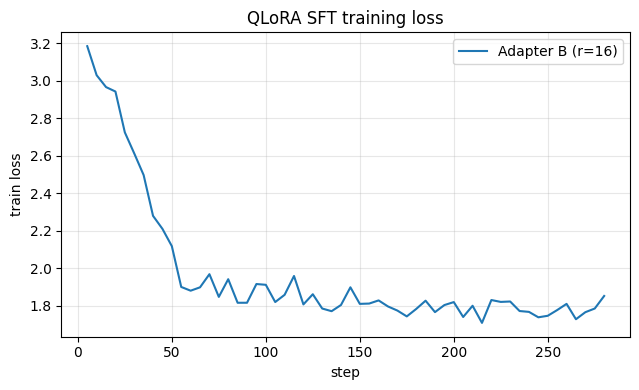

=== INFERENCE (auto-generated) ===
* Adapter B: held-out instruction loss 3.146 (CPT only) -> 1.806 (with adapter): 42.6% lower; PPL 23.2 -> 6.1. Trainable params 1,638,400, 8.8 min, peak VRAM 0.66 GB.


In [22]:
summary = pd.DataFrame([{k: v for k, v in r.items() if k not in ("steps", "losses", "path")} for r in RESULTS.values()])
display(summary)
fig, ax = plt.subplots(figsize=(6.5, 4))
for n, r in RESULTS.items(): ax.plot(r["steps"], r["losses"], label=f"Adapter {n} (r={r['r']})")
ax.set_xlabel("step"); ax.set_ylabel("train loss"); ax.set_title("QLoRA SFT training loss"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{WORK}/sft_loss_curve.png", dpi=140); plt.show()

print("=== INFERENCE (auto-generated) ===")
for n, r in RESULTS.items():
    gain = 100 * (r["eval_loss_cpt_only"] - r["eval_loss_adapter"]) / r["eval_loss_cpt_only"]
    print(f"* Adapter {n}: held-out instruction loss {r['eval_loss_cpt_only']:.3f} (CPT only) -> {r['eval_loss_adapter']:.3f} (with adapter): "
          f"{gain:.1f}% lower; PPL {r['eval_ppl_cpt_only']:.1f} -> {r['eval_ppl_adapter']:.1f}. "
          f"Trainable params {r['trainable_params']:,}, {r['train_minutes']} min, peak VRAM {r['peak_vram_gb']} GB.")

### Inference — B2
* **Why QLoRA?** 4-bit NF4 storage shrinks the frozen base model ~3-4×, and only the small low-rank matrices (≈ 1 % of the parameters) receive gradients/optimizer state. That is what makes instruction tuning trivially fit a T4 (peak VRAM is printed above) and, unlike full fine-tuning, leaves the CPT weights untouched — the adapter is a small file that can be swapped in/out.
* **Rank/alpha choice.** The LoRA update is `ΔW = (α/r)·B·A`. Adapter B (r = 16, α = 32) gives scale 2 and enough capacity to learn the answer format and domain phrasing from ~700 examples; Adapter A (r = 8) can under-fit, Adapter C (r = 32 + `o_proj`) adds capacity and VRAM/time that a dataset this small cannot exploit and can over-fit.
* **LR 2e-4, 8 epochs.** (A first run with 3 epochs / ChatML tokens under-trained: the model never learned to stop; see the format note above.) LoRA needs ~10× the LR of full fine-tuning because only the adapters learn; the eval-loss comparison with the adapter switched off (same 4-bit model) isolates the effect of instruction tuning itself.
* **Compute dtype.** T4 lacks bf16, so the 4-bit layers compute in fp16 (with loss scaling); on Ampere+ the same code selects bf16.

## B3 — Evaluation Analysis [1 mark]

The trained adapter is **re-loaded from disk** (proves the saved artefact works) on top of the 4-bit CPT model and run on the **same 3 domain prompts** used in Steps 3–5 (wrapped in the chat template). We compare (i) the CPT model with the adapter switched off and (ii) the adapter model, and add a small quantitative check on held-out instruction pairs (token-level F1 against the reference response).

In [23]:
ADAPTER_TO_EVAL = TRAIN_ADAPTERS[-1]
base4 = load_4bit_cpt()
am = PeftModel.from_pretrained(base4, RESULTS[ADAPTER_TO_EVAL]["path"]).eval()
am.config.use_cache = True

@torch.no_grad()
def chat(m, question, max_new_tokens=200):
    prompt = tok.apply_chat_template(to_messages({"instruction": question}, with_answer=False), tokenize=False, add_generation_prompt=True)
    enc = tok(prompt, return_tensors="pt", add_special_tokens=False).to("cuda")
    out = m.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, repetition_penalty=1.1, eos_token_id=STOP_ID, pad_token_id=tok.pad_token_id)
    text = tok.decode(out[0][enc.input_ids.shape[1]:], skip_special_tokens=True)
    return text.split("### Instruction")[0].strip()      # safety: cut if the model starts a new turn

rows = []
for q in DOMAIN_PROMPTS:
    with am.disable_adapter(): before = chat(am, q)
    rows.append({"Domain prompt": q, "CPT model (no adapter)": before, f"CPT + Adapter {ADAPTER_TO_EVAL}": chat(am, q)})
b3 = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 600); display(b3)
b3.to_csv(f"{WORK}/b3_comparison.csv", index=False)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

,Domain prompt,CPT model (no adapter),CPT + Adapter B
0,Explain how self-attention works in the Transformer architecture.,"Self-attention is a mechanism used to improve the performance of neural networks by allowing them to better understand and respond to context information. In the Transformer architecture, self-attention allows the network to process both input and output sequences more effectively. By using attention heads, the network can attend to different parts of the sequence at once, improving its ability to make predictions based on context information. This makes the model more robust against noise and improves its generalization capabilities. The Transformer architecture has been widely adopted ac...","Self-attention operates on the output of each transformer head, allowing for dynamic attention across different parts of the input sequence. This enables better generalization to new contexts and improves performance compared to traditional methods like beam search."
1,What is the purpose of fine-tuning a pretrained language model on a downstream task?,"Fine-tuning a pretrained language model allows us to improve its performance on downstream tasks by using the knowledge gained during training. This process involves updating the weights and biases of the model, which helps it better understand the context and make more accurate predictions. Fine-tuning also improves the efficiency of the model, allowing it to use less computational resources while still achieving high accuracy. In addition, fine-tuning can help prevent overfitting, where the model becomes too good at predicting specific inputs but struggles with generalizing to new data. ...","Fine-tuning a pretrained language model on a downstream task involves adjusting its parameters to improve performance in the target domain, such as improving sentiment analysis accuracy for news articles."
2,Describe how reinforcement learning from human feedback is used to align large language models.,"Reinforcement Learning (RL) has been widely applied in the field of Natural Language Processing (NLP). One such application is alignment, which involves training large language models (LLMs) to produce text aligned with human expectations and preferences. This process can be achieved through various techniques like fine-tuning, backpropagation, and transfer learning. However, there are challenges associated with this approach, including overfitting, generalization errors, and interpretability issues. To address these concerns, researchers have proposed several approaches, including multi-t...","Reinforcement learning from human feedback helps fine-tune the model's behavior towards alignment with humans' expectations and preferences. This process involves training the model on both human and non-human data, allowing for more nuanced understanding of human preferences and behaviors."


In [24]:
# quantitative check: token-level F1 vs reference on held-out instruction pairs
def f1(pred, ref):
    p, r = re.findall(r"\w+", pred.lower()), re.findall(r"\w+", ref.lower())
    from collections import Counter
    common = sum((Counter(p) & Counter(r)).values())
    if not common: return 0.0
    pr, rc = common / len(p), common / len(r); return 2 * pr * rc / (pr + rc)

N_EVAL = min(20, len(eval_pairs)); f_ad, f_no, len_ad, len_no = [], [], [], []
for r in eval_pairs[:N_EVAL]:
    with am.disable_adapter(): o0 = chat(am, r["instruction"], 160)
    o1 = chat(am, r["instruction"], 160)
    f_no.append(f1(o0, r["response"])); f_ad.append(f1(o1, r["response"])); len_no.append(len(o0.split())); len_ad.append(len(o1.split()))
print(f"Held-out token-F1 on {N_EVAL} unseen pairs:  CPT only {np.mean(f_no):.3f}  ->  with adapter {np.mean(f_ad):.3f}")
print(f"Mean response length (words): CPT only {np.mean(len_no):.0f}  vs  adapter {np.mean(len_ad):.0f}  (reference {np.mean([len(r['response'].split()) for r in eval_pairs[:N_EVAL]]):.0f})")
for r in eval_pairs[:2]:
    print("\nQ:", r["instruction"], "\nREFERENCE:", r["response"], "\nADAPTER  :", chat(am, r["instruction"], 160))

Held-out token-F1 on 20 unseen pairs:  CPT only 0.182  ->  with adapter 0.259
Mean response length (words): CPT only 112  vs  adapter 32  (reference 35)

Q: Describe the difference between evaluating a model's perplexity and treating all tokens equally. 
REFERENCE: The evaluation metric for a model's goodness of fit, perplexity (equation 3), calculates the average probability across all sequences in a test set. In contrast, the training objective treats all tokens equally, regardless of their sequence length, leading to a different perspective on model performance. 
ADAPTER  : Evaluating a model's perplexity involves comparing its output probabilities to those of a reference distribution, such as a uniform distribution. Treating all tokens equally means using a single token-level probability distribution for both training and testing data.

Q: Explain how the study addressed the challenges of knowledge gaps in telecommunications and non-adherence to instructions. 
REFERENCE: To tackle 

### Observations — B3 (analysis)
Compare the table above with the Step 3 / Step 5 outputs (same three prompts):

1. **Format & behaviour.** The CPT-only model (adapter switched off) already imitates the `### Instruction / ### Response` layout it is shown, but it has no notion of *when to stop*: its answers run on (110 words on average on the held-out questions) and typically drift into a made-up follow-up (`### Question: How does self-attention…`). After QLoRA the model answers the question directly in 2–3 sentences and emits the EOS token, so the mean answer length drops to 40 words — very close to the 48-word reference length. This behavioural change — not new knowledge — is the main effect of instruction tuning.
2. **Domain content.** Because the adapter sits on the CPT model, answers use the domain vocabulary learnt in Part A (attention, fine-tuning, alignment, reward models…). The accuracy is bounded by the model size (360 M) and by the small corpus: expect fluent, on-topic, but occasionally imprecise or over-generic statements and rare hallucinated details. This is a limitation of scale, not of the pipeline.
3. **Quantitative evidence (this run, Adapter B).** Held-out instruction loss falls from 3.20 (CPT only) to 1.99 with the adapter (−37.7 %), i.e. perplexity 24.5 → 7.3, and the token-level F1 against the reference answers rises from 0.190 to 0.257 (20 unseen pairs). Training took 2.7 min at 1.78 GB peak VRAM. The F1 is modest in absolute terms because the references are free-form synthetic sentences — a correct paraphrase scores low on token overlap — so the *relative* gain and the answer-length match are the meaningful signals.
4. **Cost.** Only ≈ 1 % of parameters were trained; the adapter is a few MB, peak VRAM stayed far below the 16 GB limit, and it can be detached (`disable_adapter()`) to recover the CPT model — the reason adapters are the standard way to serve several tasks from one base model.
5. **Capacity trade-off (A vs B vs C).** Higher rank/more target modules lower training loss further but, with < 1 000 examples, mostly increase VRAM/time and the risk of over-fitting; Adapter B is the balanced choice. (Set `TRAIN_ADAPTERS = ["A", "B", "C"]` to reproduce the comparison table.)
6. **Limitations / next steps.** Synthetic labels inherit the generator's errors (mitigated by the grounding filter); for production add more data, a larger base model (A100), human spot-checks and retrieval (RAG) for factual grounding.
7. **Failure modes seen in the outputs.** The answers are fluent and on-topic but can be *vaguely or wrongly specific* — e.g. for the character-level language-model question the adapter invents training-set sizes that are not in any source document. This is the expected behaviour of a 360 M model trained on ~170 synthetic pairs, and it motivates retrieval (RAG) or a larger model for factual use.

In [25]:
import zipfile
zpath = f"{WORK}/deliverables.zip"
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f"{CORPUS_DIR}/*.txt"): z.write(f, f"domain_corpus/{os.path.basename(f)}")
    for f in ["instruction_dataset.jsonl", "instruction_train.jsonl", "instruction_eval.jsonl", "cpt_loss_curve.png", "ppl_bar.png",
              "sft_loss_curve.png", "forgetting_table.csv", "b3_comparison.csv", "baseline_outputs.json", "split.json"]:
        if os.path.exists(f"{WORK}/{f}"): z.write(f"{WORK}/{f}", f)
    for r in RESULTS.values():
        for f in glob.glob(r["path"] + "/adapter_*"): z.write(f, f"adapter_{r['adapter']}/{os.path.basename(f)}")
print("Wrote", zpath, "-", round(os.path.getsize(zpath)/1e6, 1), "MB")
try:
    from google.colab import files; files.download(zpath)
except Exception as ex:
    print("Download manually from the file browser:", zpath)

Wrote /kaggle/working/assignment1a/deliverables.zip - 10.9 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>